# PIM-PF | Painel executivo
**PUCRS — Fase 2 · Mateus de Oliveira Ferreira**

Dados públicos: fascículos regionais IBGE ago/set 2026 e Informativo SPE set/2026. Base congelada, transcrita; versão da edição não é data de divulgação. Execute as células em ordem. O código-fonte legível está em `src/` no repositório. Não há credenciais nem acesso à API necessário para esta amostra.

In [1]:
from pathlib import Path
import base64, zipfile, io, os, sys, subprocess
root = Path.cwd() / "pim_projeto"
root.mkdir(exist_ok=True)
archive = 'UEsDBBQAAAAIAO68el0lXOhW6AUAAPELAAAOAAAAc3JjL2V4dHJhY3QucHmFVlFv2zYQfvevEAIElFCVju023ZTpIdhQtA9NgzYYsBmGcJEomy0lqiTlJk39Y4Y9DPsd+WO7I6XEbbNWiGLxeLz77vjdkQcHB79qJRxEulWyFZHuSqlbUDx6Ba27/beJbAud3WhnI9lWohP4r3XCnkTt7d86AuWEgQgiFBqxhqjU7VooqIAfHBxMZNNp4yIw6w6MFWm0AbtR8jKN3lndplEFTjjZiAhsVLlJbXQTdeBIJRrWnuNwtGPEh15YZ4PiOOLorUMYdlzy4uLi/DTIgmZvFFpc8N5JxY1w5npUfUOD0XwHbYVA8K+rJm9ev77IyXlcFLVUoigSXGq12oo44RgORmyXs9Xk9PxlzjbOdTabTq0wW1nqCiptubxcC77WW35pptDJ6XYxhTVlCSfZ5PfTN2/zm9n8+Og4Y5hbWYrCiqawwFKSPruXkmR2fDTLWKOb8D3P2LW+Dt8L/HZV+H6SMTWbs92kEnXUgGzjJJtE+HT5uAv81Kz7BuGf08jEyUnUYQ6rAgZ5zB4/lq1EJrDUXXcil61L0R70yuXzo/n8wRW1bB5WP35QvZLbXq2hBHSyEarL2W+APKxENMzc/kME0zXiAJVGVhC3NqKUFQzkk20tDA4ZOoC84z46cmLjxMcs6wg44voFeIgnQyDCGG1i9hJZbLagyMz29i8lK83CKuug6fLK8ZGdvNUfYxzT9yfdCuRRmXDrTE2SmB3+cdgcVheHLw5fHb49rP8kPLVWlTA5sWjK0BCwKUMOFHflxKbez6jJm/eVNPHAq/zC9GJAI2x+x/S3wlqsT9oylPNG95TMkXws3WN+3MBVQVyXaMDTPHbagcoX6SWU73VdFzWUTpt8liIS19ui1qYUSlqXL5/Mf06fHh3hO8d3ge+TVZIERA20shaktTqJjP5o8cNPEOVq4cpNjAWXttCIFOOBxuZnmLWBh/SYnNCvhfOKg074SSmlunf58REGabgBiXuKyIoAkkKndOaGUwvx5MUizUMWp+Q0SPhHI50oLq+xWcWGI3ccZhbVR/gcOupm8Q1DECwznLAwMB96udUs8/CZ3cD86THLhr7Fw3jPHt+Iq0qu0V6cpExcOQRc6QIZwjK/wSnbY3oG/H60QzDxgJuNqLQPiyUDfIcWY5Lwqm86G49qqWhtb5DstpQyfw4Km6v0rTmfJ5Q44XrT+kz5rGMCIweXSiDbo+VP+KT4Plvd70mDp0Aedq9mN9jUdtMbv2I3pSnf0ViKU0FYkHDAehKVKqfxkpUKkKFYs1BqYdlqebRaMlkxZIoSW6HsoNdKHFxgKUpkINY3W3k6MKgarFQsLXC0C+lyhdaVLnN2NluCUivmh49y9vlsEQRU5exswSiy4CPCV0RsT3W+rzp/QPUuDZSoawGGVAzgWRaPvSP1reTRbI/HPm9IhI1FJ4y/09huMUO0fnfTZEfzase8xebe3CydLWiHYAtSUSr/J+kdtjb9Vc6D5WKcukt/EOyBwATGVyHxiQdwRQDuXFIevlDByRAHt52SuA+f2VDs44MrWu1GTxn1YifbXnyhRJ62YHzpk0064jjSuLHxV1nzJxJcKw3VD+Kf3gw+d1M0LWErJMrwc/dAZrw8pCW9Ybj7gH0dKmRihoN0n55Ujbi+VLvAjV3yDUAKh9BTKAPYb6MYFfFugOcdqdKSJQtjXzWrh1fRU+ZB78HKwbrSlUhxy4TKW+oEkhp7icp4Mq2pcLBuhvwm3+Lfh4cHvfR7Mvrzgu9io0flXm+5l0u2+u4KchZ2LMXTtfc+Bxv+5x5x5g+P+zbsKE5gmd/SlA0EYNlgLUAokLCZCrwdRH7c6kaQxIo13TC01/PpuxOhHnlIw7UKd8aMXZ6uAabAfK5lS/Y88EGM/iuO9lq8uRhZxmHOXyKw4HCv8Mxk2Pq3eAEFXfgTwJPrh90/XMsqTvee53j2iZjykZCz0m7vToZWmwZT/wkBc5Qz3+evQs+n2jd43RqUkwmWaVFQUEWR56wo6AZYFCwbroKT/wBQSwMEFAAAAAgA2bx6XRFoHYRdFQAA9DMAAA8AAABzcmMvcGlwZWxpbmUucHmlW0uP3MZ23s+voC3YRWrY7Mc8NOoRBYws6VqAda1oHMdBo0FUN4vd1PAlkj3T7blzl0E22dxN1kEWwQ3gXYIAd5n5J/eX5Dv1YJM9LcVOBFvNqjp16tSp865SVOapVfB6mcQzK06LvKytd2ge6O8PVZ65VvUxiWtx5FpLXhGkGc1WabGxeGVlhekqeBaiA/8V4UFE2KurRPAy85I4w2+Q5qFIzFLfyb73YlGKqorzrDtDZJVIZ4kw0O+BO09f5wCu9Zy81FNqXlcSdeXVFfeoLaqCz4VX8TJO+dogubx4/+btxU+G3pTXRZLXtKntp7eqhM0uFgvmPITzig19yS0mdbNvGtx4Yl0QWXJwvTO2KHmxDPLZBzGvJcQiV8Tr8Wo1o6/Kapa8EoHpPHj//fc/+HQ0dhBEcSKCwPGwVJ5cC9vxCl6KrK4mw+nB+4u/8wm4z0Je837Jb9i59f3f/tDuLMp8DjJFiKH3ry71ENCtkrpC38uLy28b+Go5y3kZyv4XbSw3WHSZg1f9Ik49JSTsIMpLq7DizLKxqAvsLmFzX77QRDpjq/DSqzAubU21/0O5Eq5Yx1Ud5Fey5Ry8uLh85bNlXRfVuN+P6sKLZwvhLfJrb1b232ThqqrLmFfBq3Vd8jq+xqcIQhH8UPKsAhEpn/O8/05UH1dxxYNmRhK8hWDh512ZhyvABK/jKp7z/mtezeP5Ksmr7SdNw1hIMhe8efG7VwEED4LKk/5oMDrts4PLdy0yb25uDIUR/1lAFfpF3UNrjn2WPOmFojfPs1qswrxfrGYJcM9zUfXR+WGV1auS9wS+85QIol3FIcecbZ9cNc7k/jCc98D6XiVq6veWdZqwg4NQRNDDEjKc8VS416Ik3XJTge3PnfGBhT8lUOJM/clUNunQSEHluUGC+jSTBIyHQS3WNUSsKnC+BFPZGgf9SfI5T9wN9NW95slKVD6BKGCb/QEKZCBpidS9phUEDIfAoQlbzdHgjjuEcGjKPF4UYKBtR+yW0N/1btPxYBTe9QZD5qpl2e+AJWEuwynd/0WerrVQXWqzzd6jJOe1fe24cl+OZgH4ncFOeS8hza9LjNh6cXeeJ6s0A3tYIco4D3MsItfE76JcFdSuxCLFsdJnbKQE37Qkp07sTXbwEhJ4nbOpo46mzG9shVVvY1Hmq8IFuoZqlzRckjo2ZP4vUxgJQG/wlLUnq/Ww9dAcGfeVYCiKIdNGdOp1zVpI9HhQceacW7PdWXyRP5h1tjsrNbPSPP3kOhhj5jiUYvk4ECl38+paiiIzIx56CDFwkT4+BNQDCk4iFWQc2kJekvw1CGGwynpVJF2ZJrgrqQmSPJdt8g39XYckBcMRa8HSnziyrnxfwlpwUVbpyUMiDKn69FZZ/HEFQz22SP3jbCU6GCSZRuJJPgyHpLBrfJ8T9yt3IeDy6tIu3SvH3WGZ092+YdNv2P3OjgkmdquuLtvsw4qog3BI7aiZ4z7Bjh9sLlK7u423+sxelLyKE9qrVC/8GvXq7u2QBeywctzuWW+tzOc5+bll5MkSr4ejvdgjkjec3hyGZMLdmZu6HdMhV24MB/f0lzN140UGZAGUQ6y1dyOEV2Lz/7AvSqQ/rjgs58bvUDKx2TdLfi0q6/4vGeZVsJcisyPHjbPatv8YeSFOHQO1CG1Q4V4JUfiveVLBNCIMSW3HcVybEcbKur7/lwReqIsE69V5gChA1DFWjDy9DVeUZV5WPoNXK+eCOV6W1xm322jv/0lZEavIq5h8mEbNnUP6mWkyu9yeOp60p88HbVSX938uY2GpU5Wqdf9LtuLMPTpSKCdc6Q7UUx/9VE78kXCBBMSIEN4wBzFogtui2WfvSNIRqXX37ONiVd3/ezZHDAI0dbki7x1rROU1lyzr4oirNoppy8tAX0tOugPAmOihb0Rp1/J76rQPe8JqvuZs6g8Hg8e6z2uA+02PQSXnggdzCCUC5jpQTtduRM8Bo4uNDctKUBNGf68STMUa9O1JbzPb2FpE9VF4xbwO5kueLSAAcZIEcEXLPPR/n2fCeQzi5MLLocIBIwG41M2zPUI/datVFMVrGHWbBXG4xkiQR1A9LyzzAlxDHAyd9DvEgWBgXw4n+7RoC6c9MeGbTuExyDXahvW328Exy6MYx5mwO4l5wkiYg6IAG+zl0Gsw9tDQoI7HZ5Wtwc0ZAB4QevIz3xseDkVvONBe7tqfaWbw/cxoq3uXMcqyBtK0Yk3Chf/3bv+hxdCzdYNwGMboAflN/dOpxD1hSKdqEjQ0vGa4t21hooYEF4I2tPw2vJEQ0L4a3vpaJAZhQ5XRra9b3VjIdCvrS/aGHD2Sij6LeJ0r4+wqq6qM17lREQOM7KPPZB+F0fsm4KDasHTMD4GIrjYU2nGViz0UHOh4ANmOzGfIs1JjlSEsvtJ7uYnrpcmpycZlSAjtly8cygnR3LpaNIBGzFcwS/MyLmAVVfqFyf1qvhQpp7SLdQL1rS8M45QEvBbIJ9l4KyVTIyboM/q39TbofOCBpm2BAkBbQI1DQncT+jYh710nrJDpCDRPBg5EHYUgaSf6kHT70YSgplL5g8ZZVWQ7WwaMYGQSLGrlXG2CVx723Aq9OIMhru0BiEfkVkpDNZTWPXQOh46EwbGCgzYDNQgsNIGZG0eBOj+fqVhiVyQiP9JaHJIWG1J2bAvWHVPXIRk1mJUtN6C08lyoXx+H+jQ8V62G0aqplUN9y/QCFs1sgZQiKHRSy37NNhpyWmojUTUqo9HsURkJR+kSPCD8zHbJfZqjgZXWPITbSiwijiasx6QAQXMJv3P56rtX3/xgPbZev//+rXV9E0gDIBFtJ+dlvIh3E4gdc0E+binmV74BNoeIhekcEQ0dTrbi27G+UtlZIBXO4OkY/ayAh58nOXIeOaitJOa57TYQuII4HGQ8M9LKK5JVi4RTwjq+T9+GTN0kMs3SXbt19AlbpLNH7pqMwNWhravP3F0OMaYpdGkBXUAoBUSvtjdu5srCmlbSDW2TV7ws+QaDMrFuzJ4ERKz1ex5fC6viP9OKrMlhMRMrxz8LezPpDUfjqZs9mKoLe/f/mluqYridvlsthDmI4tomepRyE4s2jjQJS14Iuzd0h467cTyzmV1QV/0cZjtzHlAli4YwHgN34HT2Yzihy4rgSF6GovQ1rAufl4UIh5miNYwrHWm7OlpiRX4jEqpY8DUlZP5ogBAX1lIgcAfFmpaEL/yjc+snyX254mQziXvoHsdTlY/JzFZtji/0zhwKksrI31s6tbMAzTiFdiBkx7pEA9x4US/9IzeNMyTyKaWHQSJ45I/IhIaUy1Nx1T8euVnwIZ9V/lDt7Sd3MyF6pjJF/+gnMDwgock9gy2BGbwiQEyepqozZdSc0wSDE7m56dSZDKbdik3DAgmVjU1hpWEa17KKNGxPAvCpIHjrRlqdUmXPIfUV6ZsseFNIo0rNCN66ku7uEV/0SbZZivtod4SJYq38plOIU0ovU/DR0B092UnOdQU900R0fSdx0G90dzJWuKbuqVbiPWn8TkmOJlPZCUQ1NTg514W7JvZMFM7ecLrTcxgj1z0cQgy27Wt9dDMOo9sttWGBVgYkl6DYgeYKqjtsg9ol+n6msimjyobkcyG9Sa2yAEKuonVYYWqQ/U968ssAKoGYy8KRHGiSGr2yQ7tNNlCedBZyaz0GtZcgAUJyy95evGLjtYzpVVQLv8FhgHC4by8xBJGsPpbSwMgBBfr48QiZIia/Awhla91hham/ltQ6d043upFrdsMbzUpIka924inavRgyDjU53zl+nDoBU6BD4RPxnz4CpYRo/YDkHdqcFrY5SZyqc4iRPIqwbuW9BduXL+A7aLPqRCr/1I1KKDh7e0kONZp3D/a2ObmxXNZD4B/JMgH76u97X6W9r0LmtE5wTPS65hjGRPGdPtSOj6MOoKv3ReiaHW1whW9vlhDNO5CKEp5/3oVWrlrEjebK3CD1LRHg73Otxqkuj6RHdVtztTIXSe2V83fwRoiCVwUxCoyLwG0v4mmcbJCOvhQf+I8r65JnVA6QY+Q8SZQQYq9l3Zzq8dhMwcbKq3T6oUnLujtSx3UiboQaYLM8oVBSjiR8JhLoI0X47NHR0fHw5ARjlFR4TffwdHR2FJkpIlyIZmh2Mh+FA1m/isPtDHEM30HdUbxYlQK7mzdzbpZ0Y6TD4hmk3mePRsenT/mAnVs1lALtweDsyRPBKJSEs3w0OzsZHA+YnEGHUCGjtIHa1dVyfGKP2F2Q8E2+qslYUx/B4demu6i+rWJyr8gWkMSwiP3hk4E7m+VrKBoCIYTLEgdJNx2Uiukw3WnWnfGyssPIlVwzRXjJXE3JNqaN/DDqaLa+iJGEuXzt0xLmno9WoUP27afkje0jb6Aylsh57I1OKW2haHHtgYAleieSgKmLL4VWVpXy0p8Q/yiEuX7uDyz4CUEclCZfGvzthKlCyNfX5LGQLikE7NHp6ZMnZ2fMTW5870wBkS2Su7TVXmF3fJaISLJKj68lSVB23UfyYCO4AVfXzOVJseS+d7KFpyFMyG9sHQt3z1S5xc9z6sg70myhod3qpLZtjlvprZGo0a5G3sjsfSn3Dhvd7P5s+PSYn2L3oLvXY7v71+GE9QdLplz3/0YuP24uGZG7pxb/gFYrOtjHrY3mlq6KwuUPRiPLt0CK85CBG9bmDxsMA3UBYJwshFIboYn5UJVuxD/fgB8LeFLOHOtrqxk2CecXiJBEVkG6qe5QrVK4xGmnCr3JN7pu1KCqsH90iXRW5jSTiu3W/T/v9pEhGYyCeTNtH8G79F6Y60/2KTIaCCLjmgOxOQYE0jxDguM+oI4oOQqaq9UOJcaQT5rrExk7frGNHbcFNnUnRLfB9//5W9c/DswC7FeJ97GsVciq2YNSbFN50xFJx9K0TYVSAjds6cADmX5PjpB2kN7/OYy5BeQI0GqO7fFFDmdt/fUf/rRnS58zA+/gt3IpVve/SBHfEeGTAOIWxXwW65LDr9T409+u8UQQZZhIfH+mlP3TCCateGh6iHhBhzQAkmkNwjoCobCrgdDxTAOilyY7bIwITHp5hRyPQY41Ne9KzXPWNcOfjM62Bmr+dMafKgM1/rx9+iCUYOIQKhFXFvDKi47/mz1KxEJmbRTt5VkTVX3eUp0GJszSB/zIeiPVZF5TBvVOvoHRMZVrQb5EGMJfwVPVS2F9k4MsK8trMcvzK3nLKtb0SgYgYFEWIk3LhGckZ5tO4dtkMcVavkGSRZSJ/LsxNepi1fla9e4kjKa7qcVhqHXRPXXX/jZX2fjm3l8fk6mJqpPXb13kEfkw3zgetcrYaAfOqNIOQwqpVZDHxkwpIttsWr0AkIiISXTn19h3MrbA3LLSVKe7/49UXgbKu6vGtpI5BGzLlDZOLAbstBXI+A85J6l4wCAvrpAvTFr3x8jgp+e7pwG7ZIfEPc0x8G5r5jX7WvcYFDnWMBZJp5dnVMCAMQ2kPLaOAjsHKjnmsyXTTFdxy1JGwD6CSQqR5C46HkcFTMdnA8fZJ0eS8i0zdryE4YemBIhbd9C/glntpwbEuAd3YLr063R5pz3Tr2XcfvbAOUEazCOn8R5br1l3evIZ3lDus6MV6nbIUKdpBSylaT6TJ7Cl4UTSQHYRvnVsIZ1V9gvUwHZlcCdNF11eaUIW/iL3Xss0gzzfwuNhGFQIOmBm7LWvjSiIqVy1qnzNdKg1k8lwc8c97OLYegKgaRn9zyHcWniXxv1b+aYOJlv+3MlVVAZochbDhlOwoZm9Y7ydrjrp1AQ6IBWoU0+K3UW3xEMTWxnKg+VFWiRU4mPqZWKg8jSXMlBQ3+SnFxTo0lXrTnZ4R8ZuEWeATdj4CMlqqX6Qcp6euGyG1gntu6G22QU5YXrFZkerJJFfulqKvCxZhSJQFH1QdpR0N/ZNeqMfMKhbZ5rJnn0R5vN6UwjZfv6M/rYSni38L4u69+L9l8+fIQfi0uuQZn25qqPeGXrlATx/9+Zt791rOgOOc0ssdRUXX+fP+grgWVVv8DPLw80tMWc8PC3WlmTLuWTKWLPknGoXJONZOH4koug4OjtXPAJfivVdJeakh7ctMMnz8wLiF2eL8QhQZsbwDIsMzmey0NwreRivqvGQ0PBbvapKou9qPkvErQbEUMKLSozNx10duvXy1iwBrAbnLK/rPB0PsQ7ivzi0HoVhePesr7b7bDn8HGsw+qx4Tm8lrb51+e6V9d//tdVWKcM76QLGeYrgsuTUFfFqfv+LfIZp1fSUc17GdHtjvaYCoCWsJE7jmgJtCruz3Hr/6uLl21cYj5O6xKRrxK0qQiG/Jx+FlHkiZAQK3b3/hcK4Z/0Cp6e4jg2NnutoCbTs0ocdjWhHJiC6vBgjGBq5QzKU6inp2PrrP/5p4J59hZ43Tewve0fuCfVeZPnYOhy4x9QYjpQOy57RV5KWviGGtdTW6MeO9hqtaakwSfahHzGzJysOIeO38eHw7svn7NBMaeCV4hyPtxOL598OybbK7dwuh82LEvVc5a5/S2WI5dC5IyZ9OwIQ5SPba/0OHIYASO97Kwl+ZF3+zXf9by5/JNxHn8B95NzJg2GHHxs70KrGqbumQD199ZsybcRu12NvFN213pqq7Z2Y7W2rg78J5xHhPCTWvNClR5KJMIcNnsGBqaRma5Lp1iNVuR85ZYq7Z5TV3P9S1fE8t67VnaoSPrZzdGxXAlSlihVSv9TLXse7gS4Idc9PPa7I5jkpr8+k5WL6IiTlVK7VLz7d0q0fVCR99Sj0vF3V9Fv3J+et6uae6Z2CplwmRRwWUWF6cttcn44LT16os2rJRyenbKz/+YCn2nahrmlnG3m173hLsQ7jhZC5k7kGGJMFwXEqVL7feZmn7D69FD+0GT2ELqKeyawD0t3BmVeEESMETL9ZZaRMCpuavn/iUzkRMtw8Z69ktkEPTb1Fks9s9hhxhyItruSTfNtRPrdTDTeMcbrFad376ZozPcWXzpYuusfN5a/LlsMgUx1QRtnMr9iYnpk9UFo1nPI1G6srtu2zJI+KixJgZNCRzsq2etNVKaTUvS0yPB+K3lNni30UUNXBoO+A6nqEhtrSsANkyDhqdnWkms2uds0FhvXdtUH5cfv8TYH0P26fv6keeo+GiXS5wMbaHuhbE5n4032JupSgTwgCcLdyeumT7SOnSe7VwxbzHIiqZR79W5mujlKPF67SgkpLdKBQ2ArRaUD/vCBuIpsQltkfUTmjKGnHv3mavqFQwAcQySAg+Q4C6EsQkDUIAjbWZuHgfwBQSwMEFAAAAAgA07x6XSRYTz2CAQAAiwQAAA4AAABzcWwvc2NoZW1hLnNxbI2T3W6CQBCF732KuZRksy/QeEHNamhxsSu29YoQAbMpuhSQpm9fYH9crRBv4Zs5M+fMrpm7XLmQiTLlh1P0lf5Ws4A+TeaMuCGB0H32CST8GNXpsRBTnoBHQ7IkDNbMW7lsB69kh6BISy4SASH5DGFLvbctARqEQLe+79zplot9nA926/8+3KtKD8f0VA8PdyjPhRpN90Ggq26/S8FpX4M05NzT5aeE7+NElIPChnh4lyYtq3h4E/n7duS4/D7zZmgTWYMU9G+TLK5FVJQiOe9b4T7lyJJnZEEYoXOyuboCR4U0guqInYvXI7QVomMZN1Jh2+9oa0Z4Y20Hx3kbSmtDa5NlsFkf6eWQNTqyp0JGz3L03SMf0PxEnacVuBvYEJ/MQ6ixeh8ox31nVGF1YFgLII5Nf9RglVqDVW4ow3LoBQtW16FBBi+BRy/5QA0BbUV5MsuwSdQw8nXlHZNLxkRpGPM6qg6rJGbHaMjLjfMO5RK9CtCw6nybDmwkaGx8mvwBUEsDBBQAAAAIAO68el1gaqPD/QAAAK0BAAASAAAAc3FsL3ZhbGlkYWNvZXMuc3FsfZBNT4NAEIbv/RVzAxsw2IOJIT1gxXroRyyteiMjOzabLAzOAvrz3UKJ0RhvM8+8mSczYQjpJxVtgwIVQ/a40g2BQqCqETpiAJZLVxMY0k0reDnJ0lW62MMU7nfbNXQf+Rs2bOH5Id2lYLhAM/duBa02HiSbOzhKW/PcW5LgmdQkmpVjs2h2HUY3YXQ1DDoSi9/ci0fZYnvY7P3pBSQZDLpefirzWli1BfKf4SqA7LD20YU6VNyzsbEBrJMXn0TckroflahZ8hMZBEIFV4U2Gv8RJE9LH19trsg02EOhTrtD8pKUxsHyMzB4zrFR5RomG/968HuLRitUFE++AFBLAwQUAAAACADAvHpdR/h95GQDAACvBwAAFAAAAGRhdGEvcmF3L3NldG9yZXMuY3N2fVVLbtswEN3nFD4AI1iULMnLpECBLIJ+0W3BWIzLQhJdkgqS4xhdFC2QVbvqlhfrfKiGSYMuPJJoze/Ne6O9mw9WeL0f9RSsGO348fM80FXt+dnrIO7sHZ3jFc/xiudDKU9eqKD31hklzvXkV71e7dTBBDWIsijF6RpNWWzFaV3U4lTyHZhNUT71NVPQbtS9iUdnrEdniaZG04r0JDFeBU/tc7nt5OfRwr8VvrZBh44dTis0NT6u/8394LvqZxePN9p4UXHxlExshCwaOOqwsf+4ez2alV5N8WseKuHQopGIQ50QabAq6PHknY7fwEdcTH387QOEprDBqclfWzcq/nvNqC5NLehWdPJsEH0LMYK5UYToFk0jsBRZYE+1wDqaQp6cwUumV70WZ4MhRmDdnSAnql2iWfP4tjSCB5+3+tpMFjq/MnZnx6vZh3ifeqcJbrBjmaLhPTXeZCHezPF+NDsefUeoU9qWPaGGDjutM5cPOt7v5sH6lZqDHW2wTkPGRBvEugPAGsjZQj7oOPO91EDT2e1hiMSVNfNlAQev2GSVu8Tjl9lMiOpKw91BJZwYHxqORNNhvQ3W2zFcXRblhR6wZAixOqiDHtIMmWklVi8RHJnol3meW+fU7pNCzyEefQC0EqXKZbQ8pRpNw2TJATvXV3DjxUJrktYGfsgCZASy++H11872ACxRcUS8HtiwJnTqRGbJEsvHeWkm7ZTxrAXwjsdhma5MJGZNbTgqKnSdBXip3Gi/LKSAnq/hQO3ijzlQHFI09chKZfipnLJ90kg+uRHEC9KAyvQQv4NKMBiizZKC3kAOYgs/omj7iG8+zLSfSDqQuMV50bhLhkby6HPQLyZUcDxC2Tg6Pejg4q+J8pbE6kUNCU24EmtyUV6qaQ56IoHTOJaOaNOWJJaGeLuBYLhkq2Kbs87OjlDcqSF+Uz2xNq2RND1cSlh7gwXlUnkff9wG1rJkyvB2JYbTBFpyfpY55kY7T9mw1Y6FiYZFTf1vOW6e89UcqN5MZn8X4sG6oBG6kr8pa0HlbGjF0wgfjf5n2kPbVDZ3WtAWanB6DZHvEdi9Nk5l/aa7CrPSJnnqcjEeYPd4XL9AP8hAimxIZxC/bMiFitg+GsxL/GKV9CGQuFclZpEVOXX8wcTZ1id/AFBLAwQUAAAACADAvHpdeCtlmt8BAADuAwAAGAAAAGRhdGEvcmF3L21vbV9zZXQyMDI2LnR4dE1TS27jMAzd6xS6gI1Qkj9ZTopBgAIdFO0J1MaYEdBahe1sBrlMMes5RS5WPlJ2upEEieT7kDpMcU5vF7dz4VJR7e3O7nitZKG6sQ22FhfOUk38zscGC5nDltxcJECeSJ87LD1X22u1cigVONZ9y28vDi8cggjgVKTAu1st8+M9/s1jnDWD+BoRjlEklIBAjrEo1MFWDRMJdWce43T91JxecnqLp6pVjQzkwCfIwuVa8zT8Ttd/2f7K02mYl0GTvVDsBEdEiuCwLWLb3twNNzy5LQQdH4L1iPX1aitOHhyHaYzvL+fXXBKdWOZZAIeiBrQBwgkyTt4c4p8UNSGIE3AfOVwZHJ3wDYgP5iGxdfY4TDHNq6Bbp1k4tr3aXZrZCpz5OX9c/09pyfY5jsvKsEOnHAdDg1MLeijaaye8su3MU8r2NNj7OA5pypsxJPrgB2mDnXZDZ0hezTO68BjPb3lVqZIq0iTwrsRf1NPJ9Dwp3PI4rk3YRlANaWWvtINlqoFuIC7au7jEia0qPEnmUaOAJuhaRkuQ6DsyHms8sUXnMtEyf72krd2GS0GIyBBgGnrzEBfk53m+edNpLzyUNatGod1b/JTAc3bM6fo5bzT5q0hBdr+0juQ7rVIDf9gvUEsDBBQAAAAIAMC8el1ifpWLEAMAAOEFAAAcAAAAZGF0YS9yYXcvaW5kaWNlc19hZ28yMDI2LnR4dEVUS44bRwzd9yn6BIUqforkMjaCAQI4GMQn6GSERIAtBZJmE/gyRtY5xVwsj2xZs2OzWazHx/fqw2W7Hr98o07z2+jSaGrv6+jaSGJYRazmgmg2nW6jcmJMhIibj1F1iOY0rYiUVJafvm7/nE/b9Ud3akRDY69VlV49zSRm9exTZv61hlrWNVDmNLlSzKOiAWAzxvK8Xd6+3zuP3obT8BVQcCQEXYY1oBZgxF8jrs7RMBTvd3STmooaJqG5hmCUTrr8dvjz+Pbvef31fHk5XG+H/ZIAKu8OVNYcEGSNaDN4jB0UT/CGFGleH44JbWoG0kNHHgtmj+Xj4R15aJsCSFlGTMCDsj6YuFqx89gR4ujMVDe1KpI+fGfIJtPyfLictq+/v/5xfqek68gBEcmgiUZDmzJrRtSGTefKsYRjgYMB0IyLxGHkuR5vmYrlw/bXcXtgZp/iicJCoIfE5aPquc2uYUkm+2AEmHBg12vMRhBUTQHMYsunI7SxPh0u2/EhEW8xoJ26WV1D73Kw4Fofu0yrnKCEdwHFlL0ORBdhiHDWl5+vf7/9dznezuvn7XT7QQ311FxewoqVh6CNdETgGxFD250xjFCDgHK/bKnyVBDqVKbOyvUwhlyO5/XlsP6ynQ7Hy4N+ab0jWjOChItgT5rAQCLoID21CTK4T6+/UJDPyuWYVHUG3dvyOfX4vL1+ufcHh8A9SnChSpaBcJSgcxR2rYhGagDch0FVuTIYzagyMACljbbTw0gwoQZPuT8AaYuyPTn5vglhsl0XqlPuBtZIS2HlKmm9fB6oGy/J+rZ+3G7bBbt+vwPKpH13FEH3fWKO3aL4KvQYDSW7+43mXRU8qayMe910p/8JM2AFL9jz6/0tCywPwrViQdyLmdGCoLzKDbFdw9G9XjK8HKxTa5Bh4D451a4sy6ftlpecr9fHfrleRSqz4Pmo/WpedB+CbJoXTOjZdnmyp67S2IE3oVDAjuTL0/n49v3hgUjBWK82ODto96ZTtsYlZl45vFcgb5ab4WWSqsPJZCodzia6/A9QSwMEFAAAAAgAwLx6XUzcTQFjAQAARwIAABUAAABkYXRhL3Jhdy9yZWdpb25hbC5jc3ZVUUFqwzAQvOsVfsBK2LIdO8cmlEAhJSQv2DamEdhWkZxD+pvQc1/hj3VWbqE9aMGe3dmZ2d6/ck+DH+jmb3SbztQXVj0M/OFHjlSZhnKzJm1NQbowlTpwmO9kzQqfpbGkV6Yi3Rirjt2bmz999uzDuYtTRzpNSlNuajyr9hx4vKCJSLfC2JCuTau2XWItsU1Xwlf+TKqj89kOQ+cuOydq8GJzbUrUItXcNOrQhZGHl+urx5jIaQiopRbkG744FgeVOACa+Gu1d3CY7brALgpcy+4COuWt1WN8n7+Cm3x24nHy0tEslrDdUtGYMqmDsiceOxc8xkoSOQRMnjpJHge+9iLLtCKsFhEp0JVkySN8g9VKEYFJo5KVnG154gCV6Xe1jLbLGf7ncrr2lPhzlBIGLHzveZIeH6P/7aECmIiDhL847rxON7XLsdTOu/kel0BwIaQJwKpN4Oj6ZU1KTDTLYb8BUEsDBBQAAAAIAMC8el273KCOxAMAAIYHAAAcAAAAZGF0YS9yYXcvaW5kaWNlc19zZXQyMDI2LnR4dE1VS24cRwzd9ynmBA3+ikUuI8MQEMCGYJ+gEw2SAWxNMCNtDF3GyDqn0MXyitWSvCOquvh57/H1zWW7nr49C4k9M/HanVs/VCTNGyJZSZtTnXm6KyJaOa0boobIc0S6ttazVaSqdWurIc0eZXKv21Qiqqj3SF9u3npoz+PUufO8Z/Ue9bqz5P463WbEHF3rlqzpfOFISHXWcNlnpJQyIzKat5LhWdNxz66/9ODP+z1JzScYTytSbzq6ceShxvMsk+b0jsZiRq7Vl2BSqe9QRUN1+e379uP8sF1f68gqAFPqVQSLVfag7ju2jAyI+sooHYfE+KYFSV8tknTSIrI3ZtZClrvt8vLztUZiFhk1mFdlFkfUVw3LEdEKLtpAItZQpzbT4JOs1CA32iH7GhaURb1pBi9fjn+dXv49Hz6fL/fH6+NxlsOHgnQ0X7DoIRPcvepHCNSOIxEGOYmaBARGoJ7dR0DewdZIxF1j+XB8HyYbtGHze0GVKkO9hY2c2iUmpWDUqzJeZXWPZ4ETK7x9nHSV3pa74+Vh+/7H05/nHa4BCDCb0ECnMYADzdDEhDCiDRnjjNEC4GIIP4mlXgS1mGAqOU+JkDfP5Wb7+7S9jWFiWkNG817dY+1qtbAUFEGjV82hfnyNRVSM4eheSsloUuoOkzXnWD6doKrD7fGyna7vxBP1EmdAklbLByHh4egQeHETqjPxqFsI29inCIFPUEWYS7g6s5SI5eP1n5f/LqfH8+Hr9vD4CpwQNo6HfrSt0cXRp9HqGoyxDDsqHIDVsBWcAziFChPlESW22ioC1OEEMSscKIDE8uV0PtwfD79vD8fT5Y0m5IOWBhHAyWw4AsfQ16AOvbBX04zMELXVrWMbW53J9JXRMxahV5Stky9fh6bvtqdve6UpoiGZXAMqKomCbmtFQ2u7+NgdE4Mio+wVSM8hQoChFhD92HU3Gsu5PbyvJ9hNqQWE1Rg1nTzINBPwpa10NDakF3PgRgBt2Ziqy7SKRqnTpiTEeRncbIcP2+N2gTbeq1E2ngxj22OaS1OsR2mCzDHriLBDmXXrZIM4GvC2siP0577bo2HXrEi6xVwg6h66eNqdFH5Fyn3+Mlpm9N0MpzXT+CkM/GJFeva6VOq703ccTbVjpJwDD8/n5dP2OOqdr9c3QeCng02YOyrYLqsdNRv2VSZokN3UMwx96t5MhrkN52s0Cc3xogbL8WNbbs+nl5+/rFQz4903xcxLf5K6W4L1cm6c9cY59CeAL8ewiKLX/wMNMrxhLpfj99iX/wFQSwMEFAAAAAgA7rx6XU7bKcRnAAAAfQAAABAAAAByZXF1aXJlbWVudHMudHh0HYw7EsMgDAV7nYVognA+BXAXJaZgAphYcpHbB1zuvnnbua0sMRCS8Q7aUfsvBot0n7in75FEz93ZaSprL5uW/IrB4dP4BU4epxvSYvwD5J0/WS8l8d5makgCUVap25rKiF3RDmnhD1BLAQIUAxQAAAAIAO68el0lXOhW6AUAAPELAAAOAAAAAAAAAAAAAACkgQAAAABzcmMvZXh0cmFjdC5weVBLAQIUAxQAAAAIANm8el0RaB2EXRUAAPQzAAAPAAAAAAAAAAAAAACkgRQGAABzcmMvcGlwZWxpbmUucHlQSwECFAMUAAAACADTvHpdJFhPPYIBAACLBAAADgAAAAAAAAAAAAAApIGeGwAAc3FsL3NjaGVtYS5zcWxQSwECFAMUAAAACADuvHpdYGqjw/0AAACtAQAAEgAAAAAAAAAAAAAApIFMHQAAc3FsL3ZhbGlkYWNvZXMuc3FsUEsBAhQDFAAAAAgAwLx6XUf4feRkAwAArwcAABQAAAAAAAAAAAAAAKSBeR4AAGRhdGEvcmF3L3NldG9yZXMuY3N2UEsBAhQDFAAAAAgAwLx6XXgrZZrfAQAA7gMAABgAAAAAAAAAAAAAAKSBDyIAAGRhdGEvcmF3L21vbV9zZXQyMDI2LnR4dFBLAQIUAxQAAAAIAMC8el1ifpWLEAMAAOEFAAAcAAAAAAAAAAAAAACkgSQkAABkYXRhL3Jhdy9pbmRpY2VzX2FnbzIwMjYudHh0UEsBAhQDFAAAAAgAwLx6XUzcTQFjAQAARwIAABUAAAAAAAAAAAAAAKSBbicAAGRhdGEvcmF3L3JlZ2lvbmFsLmNzdlBLAQIUAxQAAAAIAMC8el273KCOxAMAAIYHAAAcAAAAAAAAAAAAAACkgQQpAABkYXRhL3Jhdy9pbmRpY2VzX3NldDIwMjYudHh0UEsBAhQDFAAAAAgA7rx6XU7bKcRnAAAAfQAAABAAAAAAAAAAAAAAAKSBAi0AAHJlcXVpcmVtZW50cy50eHRQSwUGAAAAAAoACgCSAgAAly0AAAAA'
with zipfile.ZipFile(io.BytesIO(base64.b64decode(archive))) as z: z.extractall(root)
# Colab normalmente já oferece as dependências. Instale se necessário:
# %pip install -r pim_projeto/requirements.txt
os.chdir(root)
sys.path.insert(0, str(root / "src"))
from pipeline import main
resultado = main()

{
  "fatos": 741,
  "h1_n": 152,
  "h1_ok": 152,
  "h1_max": 0.049415471734713945,
  "h2_n": 128,
  "h2_changes": 128,
  "h2_mean": 0.24819476562499998,
  "h2_max": 3.0378400000000028,
  "h3_n": 741,
  "h3_ok": 741,
  "quality": 100.0,
  "best": {
    "modelo": "ARIMA(1,0,0)",
    "MAE": 1.1114729494088127,
    "RMSE": 1.309065893653359,
    "MAPE": 1.0630599203091997
  },
  "prediction": [
    102.891,
    103.256,
    103.433,
    103.519,
    103.56,
    103.58
  ]
}


## Dashboards interativos
A página consolidada permite zoom, legendas e seleção de mês nos recortes setoriais. Em Colab, baixe o HTML e abra no navegador. As seis visualizações abaixo também são reproduzidas em PNG.

In [2]:
from IPython.display import display, Image, FileLink
from pathlib import Path
display(FileLink("dashboards/painel.html"))
# Em Colab, para baixar a página:
# from google.colab import files; files.download("dashboards/painel.html")

/mnt/data/nbtmp/pim_projeto/dashboards/painel.html

## Visão geral

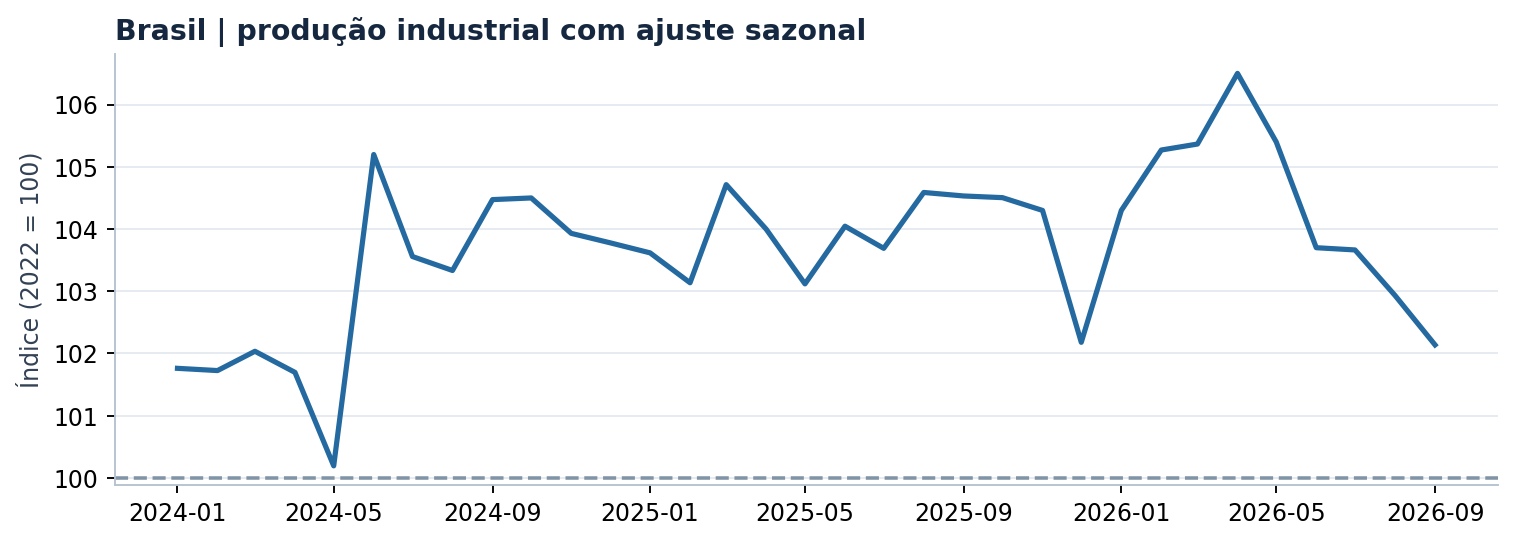

In [3]:
display(Image(filename="dashboards/01_geral.png"))

## Categorias

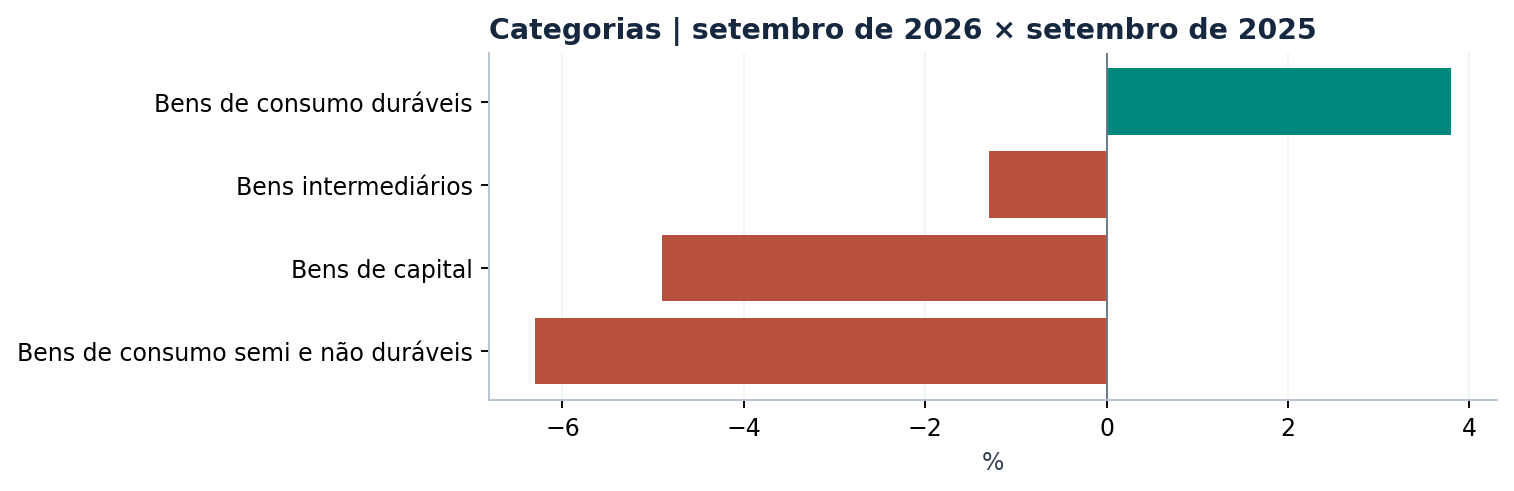

In [4]:
display(Image(filename="dashboards/02_categorias.png"))

## Atividades

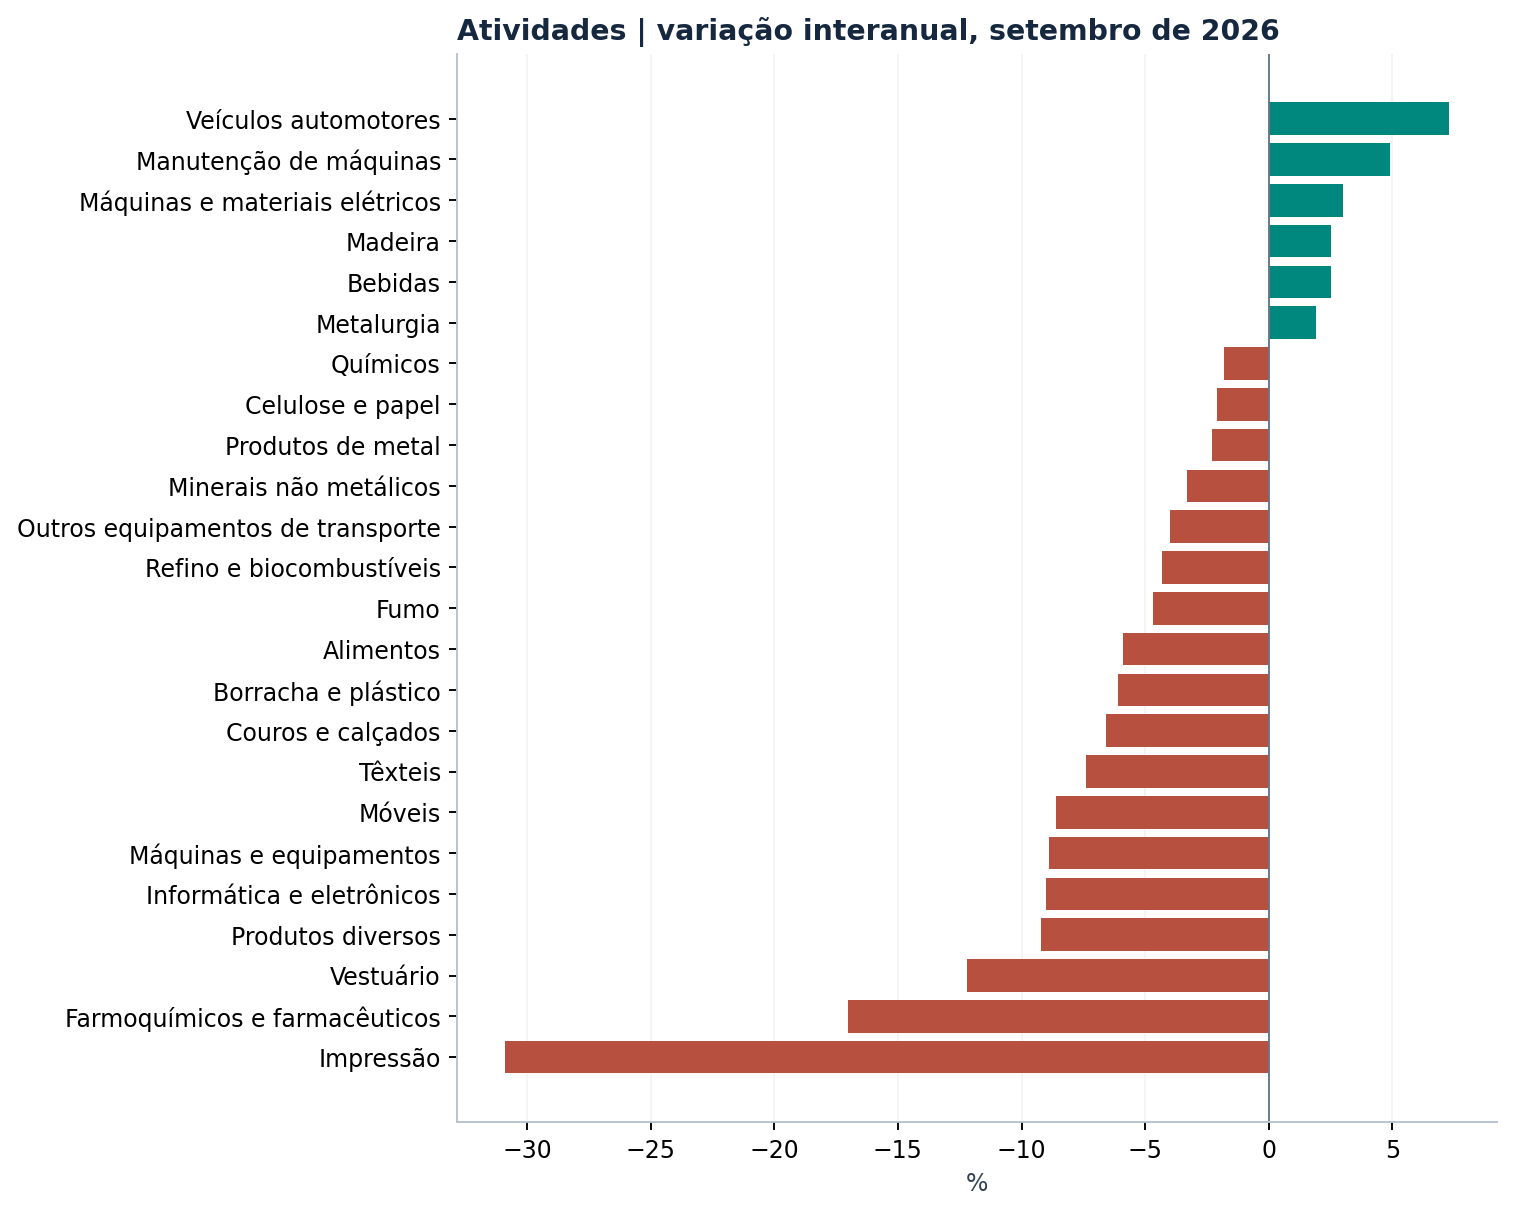

In [5]:
display(Image(filename="dashboards/03_atividades.png"))

## Regional

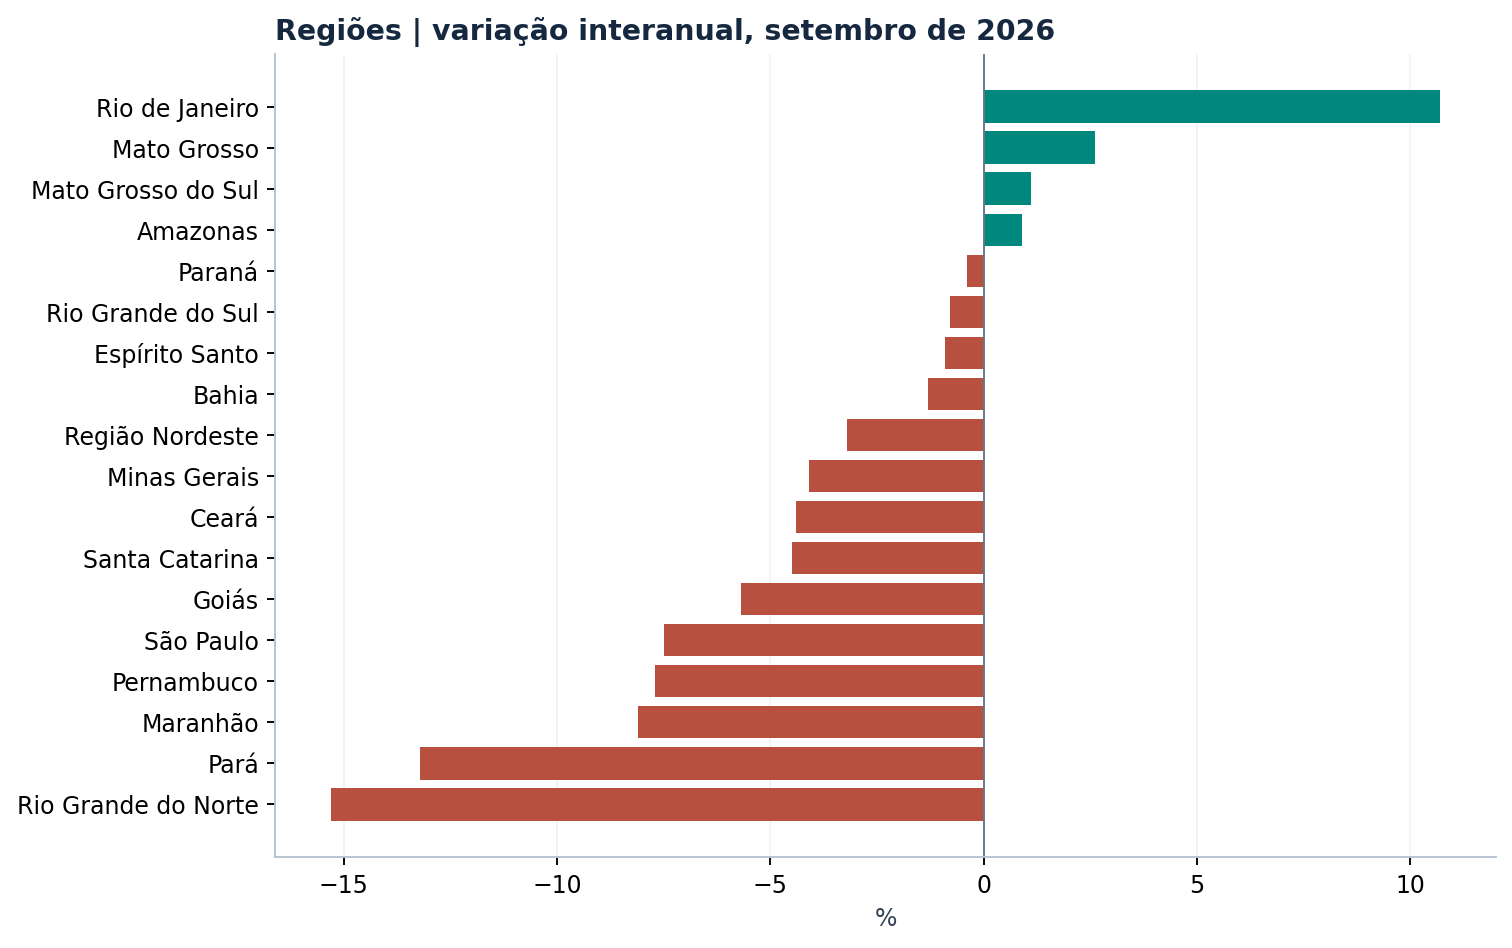

In [6]:
display(Image(filename="dashboards/04_regional.png"))

## Confiabilidade

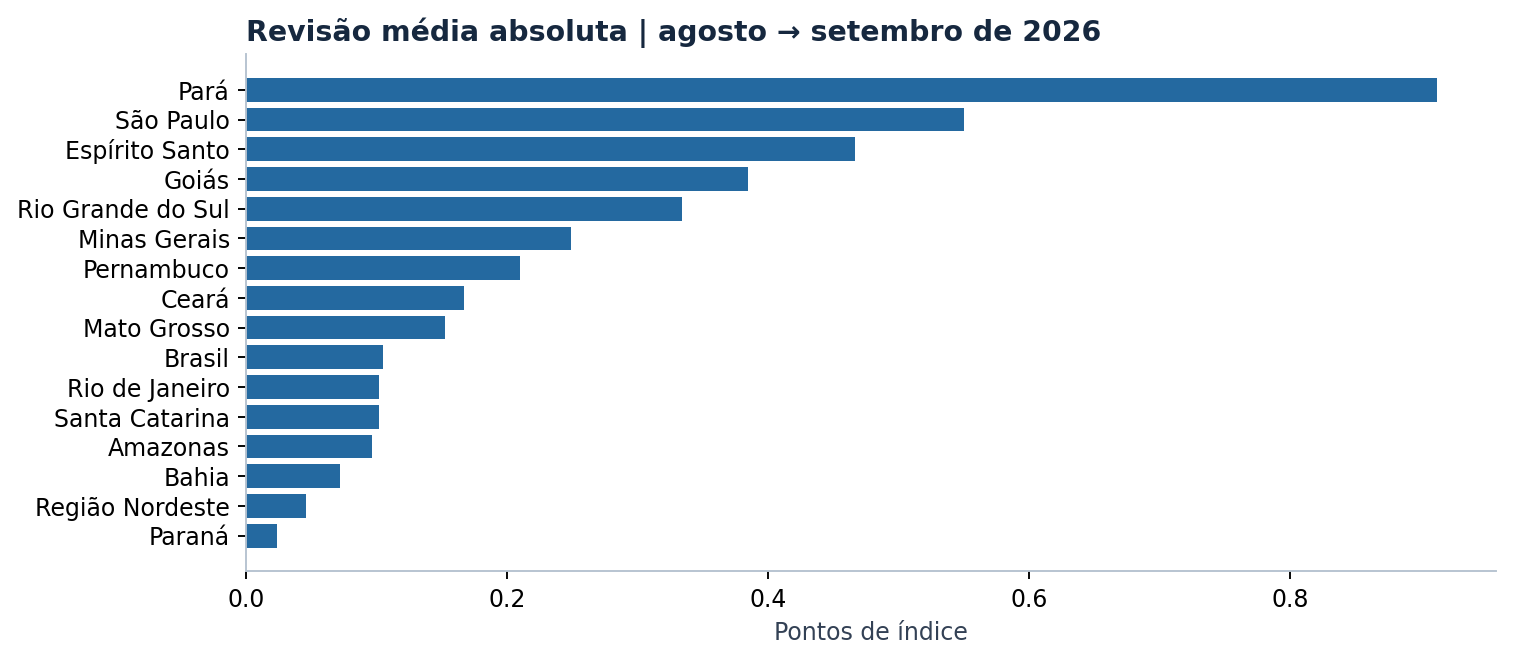

In [7]:
display(Image(filename="dashboards/05_confiabilidade.png"))

## Analytics

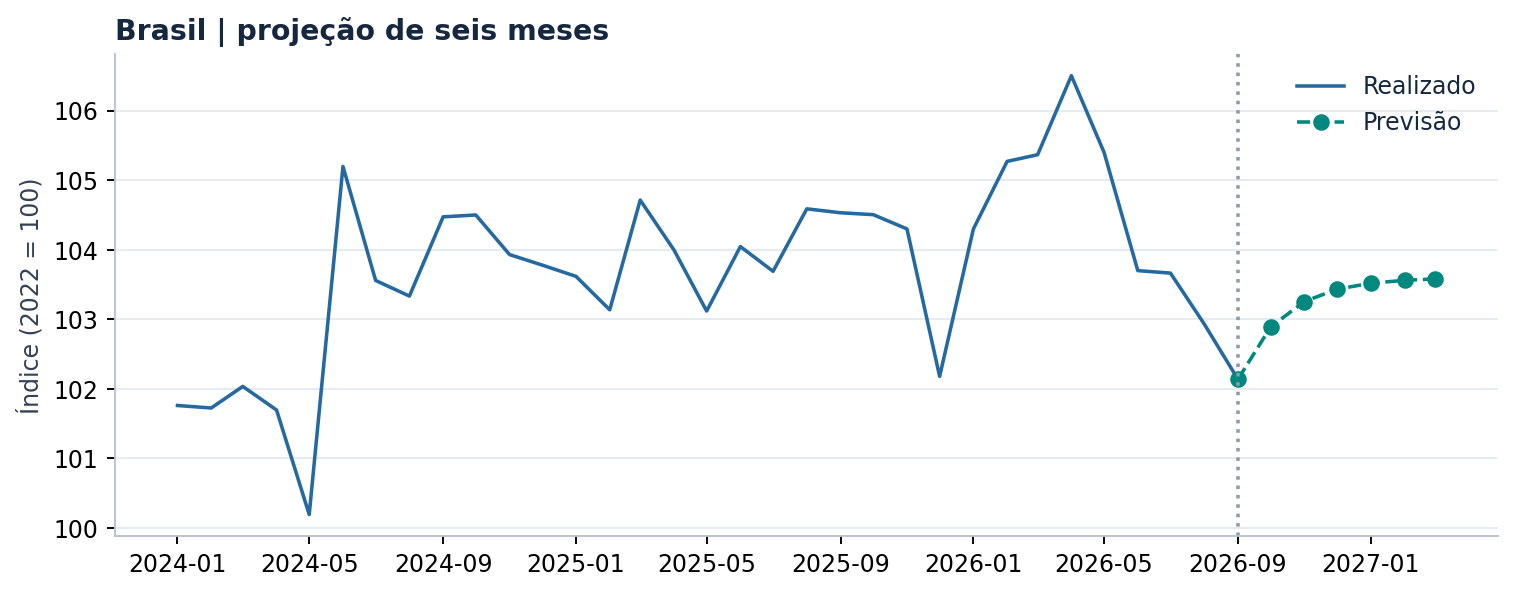

In [8]:
display(Image(filename="dashboards/06_previsao.png"))

## Evidências e limitações
H1 restrita à variação mensal; H2 em duas edições; H3 verifica SQL/CSV, não uma inspeção independente da interface. O backtest usa uma edição revisada e não constitui validação prospectiva.

In [9]:
import pandas as pd
for name in ["qualidade", "modelos", "previsao"]:
    display(pd.read_csv(f"results/{name}.csv"))

,regra,avaliados,aprovados,taxa
0,Chaves únicas,741,741,100.0
1,Datas válidas,741,741,100.0
2,Índices positivos,296,296,100.0
3,Série Brasil contínua,33,33,100.0
4,Valores esperados presentes,738,738,100.0
5,Ausências estruturais preservadas,3,3,100.0


,modelo,MAE,RMSE,MAPE
0,"ARIMA(1,0,0)",1.111473,1.309066,1.063060
1,Random Forest,1.176324,1.385286,1.126455
2,Naive sazonal,1.220168,1.532541,1.170361
3,Regressão linear,1.276909,1.665356,1.235709


,periodo,previsto,modelo
0,2026-10-01,102.890612,"ARIMA(1,0,0)"
1,2026-11-01,103.255569,"ARIMA(1,0,0)"
2,2026-12-01,103.432622,"ARIMA(1,0,0)"
3,2027-01-01,103.518516,"ARIMA(1,0,0)"
4,2027-02-01,103.560186,"ARIMA(1,0,0)"
5,2027-03-01,103.580402,"ARIMA(1,0,0)"
